(2193, 351)
0                  healthy
1                  healthy
2                  healthy
3                  healthy
4                  healthy
               ...        
2188    early stage cancer
2189    early stage cancer
2190    early stage cancer
2191    early stage cancer
2192    early stage cancer
Name: class_label, Length: 2193, dtype: object
class_label
early stage cancer        781
screening stage cancer    490
mid stage cancer          453
late stage cancer         409
healthy                    60
Name: count, dtype: int64
class_label
cancer     2133
healthy      60
Name: count, dtype: int64
[0 1]
Optimization terminated successfully.
         Current function value: 0.686134
         Iterations 6
                           Logit Regression Results                           
Dep. Variable:            class_label   No. Observations:                 2193
Model:                          Logit   Df Residuals:                     1843
Method:                           MLE   D

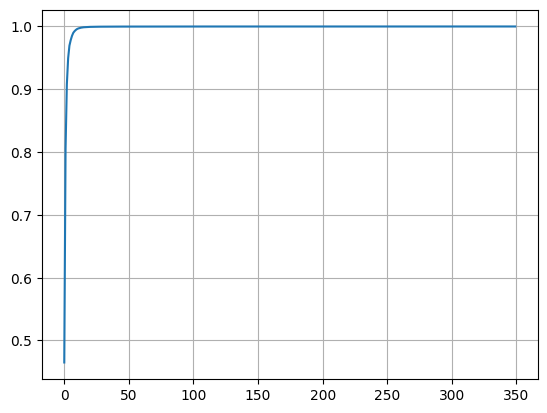

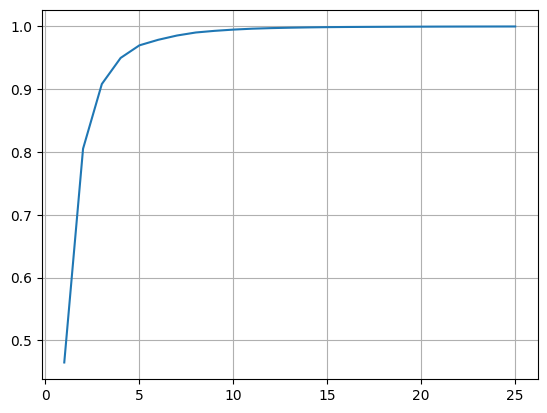

(2193, 20)

In [1]:
# --- project-root bootstrap: make this notebook CWD-independent (auto-added) ---
import os as _os
_root = _os.path.abspath(_os.getcwd())
while not _os.path.exists(_os.path.join(_root, 'data', 'raw', 'Train_Set.csv')) and _root != _os.path.dirname(_root):
    _root = _os.path.dirname(_root)
_os.chdir(_root)
# --- end bootstrap ---
### Healthy vs cancer (comparison method)

### Preprocessing for cancer vs healthy

### Import Libraries
import os # importing operating system library
import numpy as np # importing numpy library
import pandas as pd # importing pandas library
import matplotlib as mp # importing matplotlib library
import statsmodels.api as sm # importing statsmodels library

# ### Access directory
# os.getcwd()
# os.chdir('/Users/tech26/Desktop/NUS/ACADEMICS/Y1S2/IT1244/Project/Code/IT1244-Final-Project') # change directory as neccesary

### Read Data / Visualise
trainp_data = pd.read_csv('data/raw/Train_Set.csv') # access training data
trainp_data.head(5) # information on first five data points
print(trainp_data.shape) # dimensions of data set
trainp_data.describe() # statistical information on data set
trainp_data.isna().sum() # check how many data points missing
print(trainp_data.iloc[:, -1]) # view response variable (status of cancer)
print(trainp_data['class_label'].value_counts()) # distribution of response variable (status of cancer)

### Merge cancer classes together into cancer class
classes_to_merge = ['late stage cancer', 'mid stage cancer', 'screening stage cancer', 'early stage cancer'] # selecting cancer stages to merge
new_class_label = "cancer" # new label
trainp_data['class_label'] = trainp_data['class_label'].replace(classes_to_merge, new_class_label) # merge classes
print(trainp_data['class_label'].value_counts()) # check dataset if merging has carried out

### Initialise x and y variables
xvals = trainp_data.iloc[:, 0:350] # access x values
yvals = trainp_data.iloc[:,350] # access y values

### Standardising x values
from sklearn.preprocessing import StandardScaler
std_x = StandardScaler() # initialise StandardScaler
x_std = std_x.fit_transform(xvals) # standardise x values

### Techniques to remove regressors

### Perform logistic regression to identify insignifcant regressors based on p value
yvals_binary = yvals.map({'cancer': 1, 'healthy': 0}) # Convert "cancer" to 1 and "healthy" to 0
print(yvals_binary.unique()) # double confirm correct conversion of the y values
logit_model = sm.Logit(yvals_binary, x_std) # carry out logistic regression
result = logit_model.fit()
print(result.summary()) # summary of model
p_values = result.pvalues # obtain p values of regressor features in model
significant_features_1 = list(p_values[p_values < 0.05].index.tolist()) # Filter out significant features with p-value < 0.05
insignificant_features_1 = list(p_values[p_values > 0.05].index.tolist()) # Filter out insignificant features with p-value > 0.05

### Perform L1 (lasso) regularisation to logistic regression model to idenitify insignifcant regressors with coefficients zero
from sklearn.linear_model import LogisticRegression
log_reg_l1 = LogisticRegression(penalty='l1', solver='liblinear')  # specify solver for L1 regularization
log_reg_l1.fit(x_std, yvals_binary)  # train model
significant_features_2 = list(xvals.columns[log_reg_l1.coef_[0] != 0]) # check if there are any signifcant features identified
insignificant_features_2 = list(xvals.columns[log_reg_l1.coef_[0] == 0]) # identify insignifcant features

### Perform principal component analysis to identify insignifcant regressors that contrivbute little to variance
from sklearn.decomposition import PCA
pca = PCA() # initialise PCA with default parameters
x_pca = pca.fit_transform(x_std) # compute principal components and transforms data into new feature space
explained_variance_ratio = pca.explained_variance_ratio_  # Get explained variance ratio for each component
cumulative_explained_variance_ratio = np.cumsum(explained_variance_ratio) # sum computed variance for certain number of components
import matplotlib.pyplot as plt
plt.plot(cumulative_explained_variance_ratio) # plot cumulative explained variance ratio
plt.grid(True) # add grid to the plot
plt.show() # show graph

chosen_num_components = 25  # plateu cannot be read accurately so limit x axis to [0,25] and plot again
plt.plot(range(1, chosen_num_components + 1), cumulative_explained_variance_ratio[:chosen_num_components])
plt.grid(True) # add grid to the plot
plt.show() # plateu can be read

chosen_num_components = 5 # there is little to no change in cumulative variance when more than 5 principal components are involved in calculations
pca = PCA(n_components = chosen_num_components) # initialise new pca with no of components = 5
x_pca = pca.fit_transform(x_std) # compute principal components and transforms data into new feature space

original_features = xvals.columns # all features
significant_feature_indices = np.where(cumulative_explained_variance_ratio <= 0.95)[0] # identify festures that are responsible for 95 oercent of variance
significant_features_3 = list(original_features[significant_feature_indices])
insignificant_feature_indices = np.where(cumulative_explained_variance_ratio > 0.95)[0]
insignificant_features_3 = list(original_features[insignificant_feature_indices])

### Perform correlation analysis to identify insignifcant regressors that are are highly correlated
correlation_matrix = xvals.corr() # find correlation coefficients between each pair of variables
mask = np.triu(np.ones_like(correlation_matrix, dtype=bool)) # mask to consider only the upper triangular matrix and ignore correlation between the same variable. Output is true and false
correlation_matrix = correlation_matrix.mask(mask) # apply mask to correlation matrix
significant_features_4 = list(xvals.columns)
insignificant_features_4 = []

for i in range(len(correlation_matrix.columns)): # Loop through the columnns
    for j in range(i): # Loop through the rows
        if abs(correlation_matrix.iloc[i, j]) > 0.8:  # Adjust the threshold as needed. Set 0.8 here
            colname_i = correlation_matrix.columns[i] # first compared feature
            colname_j = correlation_matrix.columns[j] # second compared feature
            if colname_i in significant_features_4:
                significant_features_4.remove(colname_i) # update the significant features
            if colname_i not in insignificant_features_4:
                insignificant_features_4.append(colname_i) # update the siugnifcant features

### Decide which features to remove

### check lengths of features to be removed
removables = {}
for feature in insignificant_features_1:
    if feature not in removables:
        removables[feature] = 0
    removables[feature] += 1

for feature in insignificant_features_2:
    if feature not in removables:
        removables[feature] = 0
    removables[feature] += 1

for feature in insignificant_features_3:
    if feature not in removables:
        removables[feature] = 0
    removables[feature] += 1

for feature in insignificant_features_4:
    if feature not in removables:
        removables[feature] = 0
    removables[feature] += 1

len(xvals.columns) # no of features in\ dataset

drops_2 = []
for feature in removables:
    if removables[feature] >= 2:
        drops_2.append(feature)
len(drops_2) # 348 variables removed # 2 variables preserved

drops_3 = []
for feature in removables:
    if removables[feature] >= 3:
        drops_3.append(feature)
len(drops_3) # 330 variables removed # 20 variables preserved

drops_4 = []
for feature in removables:
    if removables[feature] >= 4:
        drops_4.append(feature)
len(drops_4) # 0 variables remnoved # 350 variables preserved

### drops_3 selected to prevent underfitting or overfitting of the model
xvals_filtered = xvals.drop(columns=drops_3)
xvals_filtered.shape

# xvals_filtered to be used as dependent variables used to build the model
# yvals to be used as the response variable used to build the model


